# Poster session figures

Figures for the 61 × 85 cm poster of *Ranked Right, Sized Wrong: Ensemble Spread Fails Silently at Streamflow Extremes*. Paper Figs. 1 and 2 are notebook 02's figures with the type set to the poster standard (§4). Each figure is built at the exact physical size it will be printed at, so the point sizes in the code are the point sizes on the poster. Minimum type: 13 pt ticks, 15 pt axis labels and legends, 14 pt annotations.

| output (`figures/poster/`) | content | size |
|---|---|---|
| `poster_fig1_conditionings` | paper Fig. 1 (notebook 02), poster type size, paper aspect ratio | 32.2 × 8.2 cm |
| `poster_fig2_ause` | paper Fig. 2 (notebook 02), poster type size, paper aspect ratio | 32.2 × 9.1 cm |
| `poster_map` | study region, gauges coloured by per-catchment UDF | 17.75 × 13.0 cm |
| `poster_hydrograph` | one catchment, one flood the ensemble band misses | 17.75 × 8.0 cm |

The notebook is self-contained: it imports only `src/config.py` for paths, and repeats notebook 02's style and metric code rather than importing it. Every number comes from the files the repository ships, using the same definitions as `02_workshop_figures.ipynb`. Values that notebook prints are asserted here against the manuscript. Run top to bottom in the `ensemble-postprocessing-py-3-10-11` environment.

## §1 — Data, derived exactly as in notebook 02

Same grid, target and ensemble moments as `02_workshop_figures.ipynb` §1: observed discharge in m³/s → mm/day (× 86.4 / area); $\hat\mu$ and $\hat\sigma^2_e$ over the ten members (unbiased $M-1$ divisor); corrected spread $\sqrt{\hat\sigma^2_e (M+1)/M}$.

In [1]:
import sys, pathlib, warnings
import numpy as np, pandas as pd

_root = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
              if (p/"src"/"config.py").exists()), None)
if _root is None: raise RuntimeError(f"project root not found from {pathlib.Path.cwd()}")
if str(_root) not in sys.path: sys.path.insert(0, str(_root))
from src.config import (OUTPUT_DATA_DIR, PROCESSED_DATA_DIR, OUTPUT_STATIC_ATTR, DRAINAGE_FILES,
                        TRAIN_START_YEAR, TRAIN_END_YEAR, TEST_START_YEAR, TEST_END_YEAR)
POSTER = _root/"figures"/"poster"; POSTER.mkdir(parents=True, exist_ok=True)

# the ten member prediction files (the noglacier counterfactuals belong to another study)
RUN_DIR = OUTPUT_DATA_DIR/"topographic_lstm"
MEMBER_CSVS = sorted((p for p in RUN_DIR.glob("*_preds_member_*.csv") if "noglacier" not in p.name),
                     key=lambda p: int(p.stem.rsplit("_", 1)[1]))
M = len(MEMBER_CSVS); CORR = np.sqrt((M + 1)/M)

# grid from member 0; column j is catchment j in every array below
_m0 = pd.read_csv(MEMBER_CSVS[0], index_col=0, parse_dates=True)
stations = list(_m0.columns); dates = pd.DatetimeIndex(_m0.index)
assert stations == sorted(stations), "station axis is not sorted"

# observed discharge m3/s -> mm/day
_obs = pd.read_csv(PROCESSED_DATA_DIR/"combined_streamflow.csv", index_col=0, parse_dates=True)
ST = pd.read_csv(OUTPUT_STATIC_ATTR, dtype={"station_id": str}).set_index("station_id")
y = (_obs.reindex(index=dates, columns=stations)
         .mul(86.4/ST["basin_area_km2"].reindex(stations), axis=1)).values.astype(np.float32)

# members kept (the hydrograph draws them); moments reduced in float32 as in notebook 02
members = np.stack([pd.read_csv(p, index_col=0, parse_dates=True)
                      .reindex(index=dates, columns=stations).values.astype(np.float32)
                    for p in MEMBER_CSVS], axis=0)
mu = members.mean(axis=0); sigma_e2 = members.var(axis=0, ddof=1)
spread = np.sqrt(sigma_e2)*CORR                       # corrected spread, mm/day

valid = np.isfinite(y) & np.isfinite(_m0.values)
yr = dates.year.values
train = (yr >= TRAIN_START_YEAR) & (yr <= TRAIN_END_YEAR)
test  = (yr >= TEST_START_YEAR)  & (yr <= TEST_END_YEAR)
resid = y - mu; err2 = resid**2
NBAS = y.shape[1]

def factor(m):
    """Under-dispersion factor: residual SD over RMS corrected spread (notebook 02 §1)."""
    if m.sum() < 2: return np.nan
    return resid[m].std() / (np.sqrt(np.mean(sigma_e2[m])) * CORR)

# test catchment-days, masked exactly as notebook 02 §1 (via its within-catchment ranks)
pct = pd.DataFrame(np.where(test[:, None] & valid, y, np.nan)).rank(pct=True).to_numpy()
TEST = (test[:, None] & valid) & np.isfinite(pct)
TRV = train[:, None] & valid & np.isfinite(mu) & np.isfinite(sigma_e2)

assert int(TEST.sum()) == 877729 and abs(factor(TEST) - 4.13) < 5e-3, "data contract drift"
print(f"{M} members, correction {CORR:.4f}; {int(TEST.sum()):,} test catchment-days, "
      f"{int((TEST.sum(0) > 0).sum())} catchments; all-test UDF {factor(TEST):.2f}")

10 members, correction 1.0488; 877,729 test catchment-days, 269 catchments; all-test UDF 4.13


### Inputs found on disk

Paths and shapes, printed before plotting. Two things the poster brief assumed were on disk are not:

- **Per-catchment UDF / AUSE.** Notebook 02 computes them in memory and writes no table. §3 recomputes them with the same code, and the paper's Spearman ρ is asserted to show the result is identical.
- **Plotting style.** It lives inline in notebook 02 §Figure style, not in a module. §2 copies it with sizes scaled for the poster.

Catchment polygons are read from `data/raw/drainage_areas/MDA_ADP_{05,07,08}.gpkg`, the path `src/config.py` declares. These are the national drainage-area files the preprocessing used. They are git-ignored and must be present locally.

In [2]:
print("member predictions :", f"{RUN_DIR.relative_to(_root)}/  {M} files, each {_m0.shape} (days x catchments)")
print("observed discharge :", (PROCESSED_DATA_DIR/'combined_streamflow.csv').relative_to(_root), _obs.shape)
print("static attributes  :", OUTPUT_STATIC_ATTR.relative_to(_root), ST.shape)
print("   columns used    :", ["basin_area_km2", "latitude", "longitude", "glacier_pct"])
for p in DRAINAGE_FILES:
    print("catchment polygons :", p.relative_to(_root), "present" if p.exists() else "MISSING")
print("dates              :", dates[0].date(), "to", dates[-1].date(),
      f"| train {TRAIN_START_YEAR}-{TRAIN_END_YEAR}, test {TEST_START_YEAR}-{TEST_END_YEAR}")

member predictions : data/output/topographic_lstm/  10 files, each (15706, 269) (days x catchments)
observed discharge : data/processed/combined_streamflow.csv (15706, 269)
static attributes  : data/processed/static_attributes.csv (269, 18)
   columns used    : ['basin_area_km2', 'latitude', 'longitude', 'glacier_pct']
catchment polygons : data/raw/drainage_areas/MDA_ADP_05.gpkg present
catchment polygons : data/raw/drainage_areas/MDA_ADP_07.gpkg present
catchment polygons : data/raw/drainage_areas/MDA_ADP_08.gpkg present
dates              : 1980-01-01 to 2022-12-31 | train 1980-2005, test 2013-2022


## §2 — Poster style

Notebook 02's house style (Times New Roman with STIX maths, Okabe-Ito colours, Type 42 fonts), scaled up for reading at 1 m. The map and hydrograph are 17.75 cm wide, the width of a poster column; Figs. 1 and 2 are wider (§4). `save` writes the PDF and a 400 dpi PNG with `bbox_inches=None`, then checks that the PNG's pixel size matches the requested physical size.

In [3]:
import matplotlib as mpl, matplotlib.pyplot as plt
CM = 1/2.54
W = 17.75*CM                                          # poster column width, inches
FS_TICK, FS_LAB, FS_LEG, FS_ANN = 13, 15, 15, 14     # poster minimums, pt
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIX Two Text", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": FS_LAB, "axes.labelsize": FS_LAB, "axes.titlesize": FS_LAB,
    "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "legend.fontsize": FS_LEG,
    "figure.dpi": 100, "savefig.dpi": 400, "savefig.bbox": None,
    "axes.linewidth": 1.0, "axes.edgecolor": "#333333",
    "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
    "xtick.minor.size": 2.5, "ytick.minor.size": 2.5,
    "axes.grid": True, "grid.color": "#999999", "grid.alpha": 0.30,
    "grid.linestyle": ":", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.borderaxespad": 0.3,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
_have = {f.name for f in mpl.font_manager.fontManager.ttflist}
print("font check:", "Times New Roman" if "Times New Roman" in _have else "TIMES MISSING -> fallback")
CK = "#000000"; CP = "#0072B2"; CO = "#D55E00"; CG = "#009E73"; CREF = "#666666"

def save(fig, name, h_cm, w_cm=17.75):
    """PDF + 400 dpi PNG at the exact physical size; asserts it from the PNG's pixels."""
    assert np.allclose(fig.get_size_inches(), (w_cm*CM, h_cm*CM)), "figure size drifted"
    fig.savefig(POSTER/f"{name}.pdf", bbox_inches=None)
    fig.savefig(POSTER/f"{name}.png", dpi=400, bbox_inches=None)
    h_px, w_px = plt.imread(POSTER/f"{name}.png").shape[:2]
    assert abs(w_px - w_cm*CM*400) < 1 and abs(h_px - h_cm*CM*400) < 1, (w_px, h_px)   # within 1 px = 0.06 mm
    print(f"saved figures/poster/{name}.{{pdf,png}}  {w_cm:.2f} x {h_cm:.2f} cm  ({w_px} x {h_px} px)")

font check: Times New Roman


## §3 — Per-catchment statistics

These come from notebook 02 §4 and §6, restricted to what the map and hydrograph need: per-catchment UDF, AUSE and NSE, and the 1980–2005 exceedance levels. AUSE uses the same definition and the same 91-point grid. The pooled all-test AUSE and the paper's Spearman ρ are asserted.

In [4]:
# ---- AUSE (notebook 02 §6): area between spread-ordered and oracle sparsification curves,
# both normalised by the set's full-sample RMSE; removal 0-90% on a 91-point grid
NF_GRID = 91
def ause_vec(se, e2v, nf=NF_GRID, seed=0):
    n = len(e2v)
    if n < 50: return np.nan
    fr = np.linspace(0, 0.9, nf); rr = np.random.default_rng(seed)
    curve = lambda o: np.array([np.sqrt(np.mean(e2v[o[int(f*n):]])) for f in fr])
    cp, co = curve(np.argsort(-se)), curve(np.argsort(-e2v))
    cr = np.mean([curve(rr.permutation(n)) for _ in range(10)], axis=0)
    return float(np.trapezoid((cp - co)/cr[0], fr)) if cr[0] > 0 else np.nan

AUSE_ALL = ause_vec(sigma_e2[TEST], err2[TEST])
assert abs(AUSE_ALL - 0.0712) < 5e-4, AUSE_ALL
print(f"pooled all-test AUSE {AUSE_ALL:.4f} (paper 0.0712)")

pooled all-test AUSE 0.0712 (paper 0.0712)


In [5]:
# ---- per-catchment UDF, AUSE and NSE, kept with their station IDs (map, selection) ----
from scipy.stats import spearmanr
rows = []
for j, sid in enumerate(stations):
    m = TEST[:, j]; yj, mj = y[m, j], mu[m, j]
    a = ause_vec(sigma_e2[m, j], err2[m, j]) if m.sum() >= 200 else np.nan
    rows.append(dict(station_id=sid, n_test=int(m.sum()),
                     nse=1 - ((yj - mj)**2).sum()/((yj - yj.mean())**2).sum(),
                     udf=resid[m, j].std()/(np.sqrt(sigma_e2[m, j].mean())*CORR), ause=a))
PB = pd.DataFrame(rows).set_index("station_id")
_with_ause = PB[PB.ause.notna()]                       # the set notebook 02 correlates (>= 200 test days)
rho = spearmanr(_with_ause.ause, _with_ause.udf)
assert abs(rho.statistic - (-0.230)) < 5e-3 and (_with_ause.udf > 1).all()
print(f"per-catchment table {PB.shape}; {len(_with_ause)} catchments with AUSE, "
      f"Spearman rho {rho.statistic:+.3f} (paper -0.230); UDF {PB.udf.min():.2f}-{PB.udf.max():.2f}, "
      f"median {PB.udf.median():.2f}; median test NSE {PB.nse.median():.3f}")
PB.round(4).head()

per-catchment table (269, 4); 269 catchments with AUSE, Spearman rho -0.230 (paper -0.230); UDF 1.03-10.78, median 2.33; median test NSE 0.754


,n_test,nse,udf,ause
station_id,,,,
05AA004,2475,0.5817,2.1756,0.1170
05AA008,3652,0.8196,1.6298,0.2137
05AA022,3652,0.7541,2.5911,0.1229
05AA027,2167,0.7046,2.1440,0.1249
05AA028,2485,0.8630,1.6470,0.0967


In [6]:
# ---- training-period exceedance levels per catchment (notebook 02 §4: 1980-2005 observed) ----
_trv_y = np.where(TRV, y, np.nan)
LEVELS = pd.DataFrame({"p90": np.nanpercentile(_trv_y, 90, axis=0),
                       "p99": np.nanpercentile(_trv_y, 99, axis=0),
                       "max": np.nanmax(_trv_y, axis=0)}, index=stations)
LEVELS.round(3).head()

,p90,p99,max
05AA004,1.637,7.211,42.995998
05AA008,2.230,6.047,19.899000
05AA022,4.149,10.635,85.499001
05AA027,3.676,9.891,37.945000
05AA028,6.603,15.298,86.811996


## §4 — Paper Figs. 1 and 2 at poster type size

These are notebook 02's two figures with the same code, marks, layout and aspect ratio (5.5 : 1.40 and 5.5 : 1.55). Only the type is changed, to the poster standard used by the map and hydrograph: 13 pt ticks, 15 pt labels, legends and panel titles, 14 pt annotations. The figures are scaled so that the paper's smallest type, its 6.5 pt legends, becomes 15 pt. The factor is S = 15/6.5 ≈ 2.31, so both figures are 5.5 × S = 12.7 in (32.2 cm) wide. Line widths, marker sizes and layout padding scale by the same S, so every element sits where it does in the paper.

The statistics are recomputed as in notebook 02 §2, §3 and §6: decile profiles, the catchment-clustered bootstrap with the same seed (`SEED = 0`, `B = 1000`), and the sparsification curves. The values the paper reports are asserted.

In [7]:
# ---- decile profiles and their catchment-clustered bootstrap (notebook 02 §1-§3) ----
SEED = 0; B = 1000
dec = np.clip(np.nan_to_num(pct)*10, 0, 9).astype(int)
dec_mu = np.clip(np.nan_to_num(
    pd.DataFrame(np.where(TEST, mu, np.nan)).rank(pct=True).to_numpy())*10, 0, 9).astype(int)

def suffstats(decarr):
    S_ = {}
    for k in range(10):
        m = TEST & (decarr == k)
        S_[k] = (m.sum(0).astype(float), np.where(m, resid, 0).sum(0),
                 np.where(m, resid**2, 0).sum(0), np.where(m, sigma_e2, 0).sum(0))
    return S_

def agg(S_, k, J=None):
    """(residual SD, corrected spread) for decile k over catchment index J."""
    n, sr, sr2, ss = (v.sum() if J is None else v[J].sum() for v in S_[k])
    return np.sqrt(sr2/n - (sr/n)**2), np.sqrt(ss/n)*CORR

S_y, S_mu = suffstats(dec), suffstats(dec_mu)
rng = np.random.default_rng(SEED)
J_boot = [rng.integers(0, NBAS, NBAS) for _ in range(B)]
dec_ratios = lambda S_, J=None: np.array([np.divide(*agg(S_, k, J)) for k in range(10)])
prof_y, prof_mu = dec_ratios(S_y), dec_ratios(S_mu)
lo_y, hi_y = np.percentile([dec_ratios(S_y, J) for J in J_boot], [2.5, 97.5], axis=0)
lo_m, hi_m = np.percentile([dec_ratios(S_mu, J) for J in J_boot], [2.5, 97.5], axis=0)

def slope_mu(J=None):
    sd, sp = zip(*(agg(S_mu, k, J) for k in range(10)))
    return np.linalg.lstsq(np.column_stack([np.ones(10), np.log10(sp)]), np.log10(sd), rcond=None)[0][1]
b_mu = slope_mu(); ci_b = np.percentile([slope_mu(J) for J in J_boot], [2.5, 97.5])

# ---- sparsification curves (notebook 02 §6) ----
def ause_parts(m, nf=NF_GRID, seed=0, key=None):
    se, e2v = (sigma_e2 if key is None else key)[m], err2[m]; n = len(e2v)
    fr = np.linspace(0, 0.9, nf); rr = np.random.default_rng(seed)
    curve = lambda o: np.array([np.sqrt(np.mean(e2v[o[int(f*n):]])) for f in fr])
    cp, co = curve(np.argsort(-se)), curve(np.argsort(-e2v))
    cr = np.mean([curve(rr.permutation(n)) for _ in range(10)], axis=0)
    cp, co, cr = cp/cr[0], co/cr[0], cr/cr[0]
    return float(np.trapezoid(cp - co, fr)), cp, co, cr, fr

SETS = {"all test": TEST, "top flow decile": TEST & (dec == 9)}
CURVES = {nm: ause_parts(m) for nm, m in SETS.items()}
CURVES_FLOW = {nm: ause_parts(m, key=mu) for nm, m in SETS.items()}
pb_ause, pb_ratio = _with_ause.ause.values, _with_ause.udf.values

# published values (notebook 02 §9 / Table D.1 caption)
for _p, _lo, _hi, _c in ((prof_y[9], lo_y[9], hi_y[9], (5.76, 4.48, 6.90)),
                         (prof_mu[9], lo_m[9], hi_m[9], (4.27, 3.50, 4.99))):
    assert np.allclose((_p, _lo, _hi), _c, atol=5e-3), (_p, _lo, _hi)
assert abs(prof_y[0] - 2.00) < 5e-3 and abs(prof_mu[0] - 2.10) < 5e-3 and abs(b_mu - 1.30) < 5e-3
assert abs(CURVES["all test"][0] - 0.0712) < 5e-4 and abs(CURVES["top flow decile"][0] - 0.2222) < 5e-4
assert abs(CURVES_FLOW["all test"][0] - 0.0885) < 5e-4 and abs(CURVES_FLOW["top flow decile"][0] - 0.2831) < 5e-4
print(f"top decile {prof_y[9]:.2f} [{lo_y[9]:.2f}, {hi_y[9]:.2f}] (y), {prof_mu[9]:.2f} "
      f"[{lo_m[9]:.2f}, {hi_m[9]:.2f}] (mu-hat); slope {b_mu:.2f} [{ci_b[0]:.2f}, {ci_b[1]:.2f}]; "
      f"AUSE {CURVES['all test'][0]:.3f} / {CURVES['top flow decile'][0]:.3f} -- all match the paper")

top decile 5.76 [4.48, 6.90] (y), 4.27 [3.50, 4.99] (mu-hat); slope 1.30 [1.20, 1.41]; AUSE 0.071 / 0.222 -- all match the paper


In [8]:
# ---- notebook 02's figure style, scaled: type to the poster standard, lengths by S ----
from matplotlib.lines import Line2D
S = FS_LEG/6.5                       # 02's smallest type (6.5 pt legends) -> poster 15 pt
FIGW = 5.5*S                         # inches; aspect ratios exactly as notebook 02
FIGH1, FIGH2 = 1.40*S, 1.55*S
PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIX Two Text", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": FS_LAB, "axes.labelsize": FS_LAB, "axes.titlesize": FS_LAB,
    "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "legend.fontsize": FS_LEG,
    "figure.dpi": 100, "savefig.dpi": 400, "savefig.bbox": None,
    "axes.linewidth": 0.6*S, "axes.edgecolor": "#333333",
    "xtick.major.width": 0.6*S, "ytick.major.width": 0.6*S,
    "xtick.major.size": 2.2*S, "ytick.major.size": 2.2*S,
    "xtick.minor.size": 1.3*S, "ytick.minor.size": 1.3*S,
    "axes.grid": True, "grid.color": "#999999", "grid.alpha": 0.30,
    "grid.linestyle": ":", "grid.linewidth": 0.5*S,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": True, "legend.borderaxespad": 0.3,
    "legend.facecolor": "white", "legend.edgecolor": "#c4c4c4",
    "legend.framealpha": 0.92, "legend.fancybox": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "figure.constrained_layout.h_pad": 0.02*S, "figure.constrained_layout.w_pad": 0.02*S,
    "figure.constrained_layout.hspace": 0.02, "figure.constrained_layout.wspace": 0.03,
}

def style_legend(leg, lw=0.5*S):
    """Hairline legend border, as in notebook 02."""
    leg.get_frame().set_linewidth(lw); leg.set_zorder(20); return leg

def under_legend(ax, leg, text, pad=0.035, indent=0.015, **kw):
    """Place a note flush under a legend box, in axes coordinates (notebook 02)."""
    ax.figure.canvas.draw()
    bb = leg.get_window_extent().transformed(ax.transAxes.inverted())
    return ax.annotate(text, xy=(bb.x0 + indent, bb.y0 - pad), xycoords="axes fraction",
                       ha="left", va="top", **kw)
print(f"S = {S:.3f}: figures {FIGW:.2f} in = {FIGW*2.54:.1f} cm wide; "
      f"Fig. 1 {FIGH1*2.54:.2f} cm, Fig. 2 {FIGH2*2.54:.2f} cm tall")

S = 2.308: figures 12.69 in = 32.2 cm wide; Fig. 1 8.21 cm, Fig. 2 9.09 cm tall


saved figures/poster/poster_fig1_conditionings.{pdf,png}  32.24 x 8.21 cm  (5076 x 1292 px)


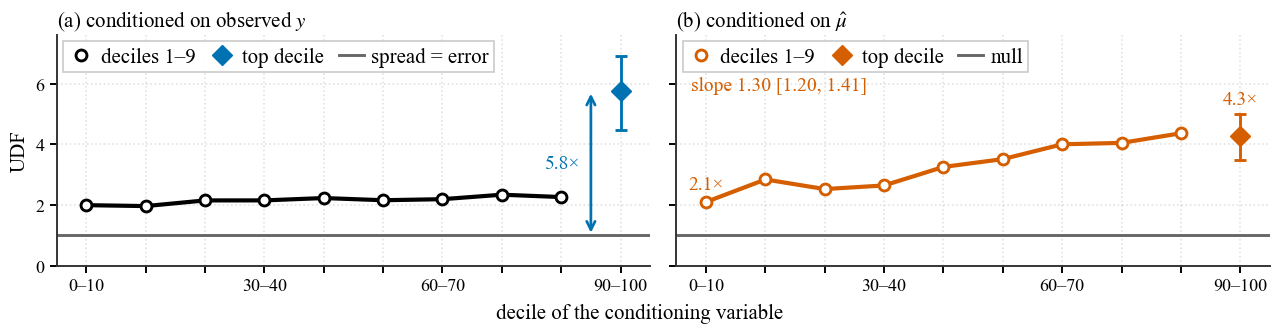

In [9]:
# ---- Fig. 1, notebook 02 §5 ----
with mpl.rc_context(PAPER_RC):
    fig, axs = plt.subplots(1, 2, figsize=(FIGW, FIGH1), layout="constrained", sharey=True)
    cc = np.arange(5, 100, 10)
    YTOP = 7.6

    def frame(ax, ref_label=None):
        ax.axhline(1.0, ls="-", lw=0.9*S, color=CREF, zorder=2, label=ref_label)
        ax.set_xlim(0, 100); ax.set_ylim(0, YTOP); ax.set_xticks(cc)
        ax.set_xticklabels([f"{k*10}–{k*10+10}" if k % 3 == 0 else "" for k in range(10)])
        ax.set_yticks([0, 2, 4, 6])

    # (a) conditioned on observed discharge
    a0 = axs[0]
    a0.plot(cc[:9], prof_y[:9], "-", color=CK, lw=1.3*S, zorder=5)
    a0.plot(cc[:9], prof_y[:9], "o", ms=3.4*S, mfc="white", mec=CK, mew=0.9*S, zorder=6, label="deciles 1–9")
    a0.errorbar(cc[9], prof_y[9], yerr=[[prof_y[9]-lo_y[9]], [hi_y[9]-prof_y[9]]],
                fmt="none", ecolor=CP, elinewidth=0.9*S, capsize=2.0*S, capthick=0.9*S, zorder=7)
    a0.plot(cc[9], prof_y[9], "D", ms=4.4*S, mfc=CP, mec=CP, zorder=8, label="top decile")
    a0.annotate("", xy=(cc[9]-5.0, prof_y[9]), xytext=(cc[9]-5.0, 1.0),
                arrowprops=dict(arrowstyle="<->", lw=0.85*S, color=CP), zorder=9)
    a0.annotate(f"{prof_y[9]:.1f}×", xy=(cc[9]-7.0, (prof_y[9]+1.0)/2), fontsize=FS_ANN, color=CP,
                ha="right", va="center")
    frame(a0, ref_label="spread = error")
    a0.set_ylabel("UDF")
    style_legend(a0.legend(loc="upper left", ncol=3, handlelength=1.2, borderpad=0.26,
                           labelspacing=0.15, handletextpad=0.35, columnspacing=0.7, fontsize=FS_LEG))
    a0.set_title(r"(a) conditioned on observed $y$", loc="left", fontsize=FS_LAB)

    # (b) conditioned on the model's own prediction
    a1 = axs[1]
    a1.plot(cc[:9], prof_mu[:9], "-", color=CO, lw=1.3*S, zorder=5)
    a1.plot(cc[:9], prof_mu[:9], "o", ms=3.4*S, mfc="white", mec=CO, mew=0.9*S, zorder=6, label="deciles 1–9")
    a1.errorbar(cc[9], prof_mu[9], yerr=[[prof_mu[9]-lo_m[9]], [hi_m[9]-prof_mu[9]]],
                fmt="none", ecolor=CO, elinewidth=0.9*S, capsize=2.0*S, capthick=0.9*S, zorder=7)
    a1.plot(cc[9], prof_mu[9], "D", ms=4.4*S, mfc=CO, mec=CO, zorder=8, label="top decile")
    a1.annotate(f"{prof_mu[0]:.1f}×", xy=(cc[0], prof_mu[0]+0.30), fontsize=FS_ANN, color=CO,
                ha="center", va="bottom")
    a1.annotate(f"{prof_mu[9]:.1f}×", xy=(cc[9], hi_m[9]+0.22), fontsize=FS_ANN, color=CO,
                ha="center", va="bottom")
    frame(a1, ref_label="null")
    _lg1 = style_legend(a1.legend(loc="upper left", ncol=3, handlelength=1.2, borderpad=0.26,
                                  labelspacing=0.15, handletextpad=0.35, columnspacing=0.7,
                                  fontsize=FS_LEG))
    under_legend(a1, _lg1, f"slope {b_mu:.2f} [{ci_b[0]:.2f}, {ci_b[1]:.2f}]",
                 fontsize=FS_ANN, color=CO)
    a1.set_title(r"(b) conditioned on $\hat\mu$", loc="left", fontsize=FS_LAB)

    assert hi_y[9] <= YTOP and hi_m[9] <= YTOP and max(prof_y.max(), prof_mu.max()) <= YTOP
    fig.supxlabel("decile of the conditioning variable", fontsize=FS_LAB)
    save(fig, "poster_fig1_conditionings", FIGH1*2.54, w_cm=FIGW*2.54); plt.show()

saved figures/poster/poster_fig2_ause.{pdf,png}  32.24 x 9.09 cm  (5076 x 1430 px)


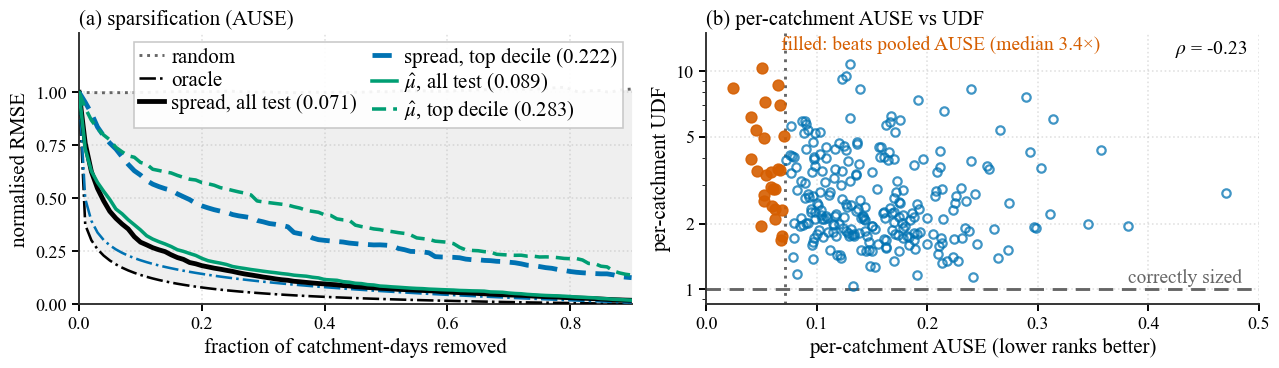

In [10]:
# ---- Fig. 2, notebook 02 §6 ----
with mpl.rc_context(PAPER_RC):
    fig, axs = plt.subplots(1, 2, figsize=(FIGW, FIGH2), layout="constrained", width_ratios=[1, 1])
    AU = {nm: CURVES[nm][0] for nm in CURVES}; AU_FLOW = {nm: CURVES_FLOW[nm][0] for nm in CURVES_FLOW}

    # (a) sparsification curves
    a0 = axs[0]
    _, cp_a, co_a, cr_a, fr = CURVES["all test"]
    _, cp_t, co_t, cr_t, _ = CURVES["top flow decile"]
    a0.fill_between(fr, co_a, cr_a, color=CREF, alpha=0.10, lw=0, zorder=1)
    a0.plot(fr, cr_a, ls=":", color=CREF, lw=0.9*S, zorder=3, label="random")
    a0.plot(fr, co_a, ls="-.", color=CK, lw=0.8*S, zorder=3, label="oracle")
    a0.plot(fr, co_t, ls="-.", color=CP, lw=0.8*S, zorder=3)
    a0.plot(fr, cp_a, "-", color=CK, lw=1.5*S, zorder=4,
            label=f"spread, all test ({AU['all test']:.3f})")
    a0.plot(fr, cp_t, ls=(0, (4, 2)), color=CP, lw=1.5*S, zorder=4,
            label=f"spread, top decile ({AU['top flow decile']:.3f})")
    a0.plot(fr, CURVES_FLOW["all test"][1], "-", color=CG, lw=1.1*S, zorder=5,
            label=r"$\hat\mu$,"f" all test ({AU_FLOW['all test']:.3f})")
    a0.plot(fr, CURVES_FLOW["top flow decile"][1], ls=(0, (4, 2)), color=CG, lw=1.1*S, zorder=5,
            label=r"$\hat\mu$,"f" top decile ({AU_FLOW['top flow decile']:.3f})")
    a0.set_xlim(0, 0.9); a0.set_ylim(0, 1.28)
    a0.set_xticks([0, 0.2, 0.4, 0.6, 0.8]); a0.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    a0.set_xlabel("fraction of catchment-days removed")
    a0.set_ylabel("normalised RMSE")
    style_legend(a0.legend(loc="upper right", bbox_to_anchor=(0.995, 0.99), ncol=2,
                           handlelength=1.2, borderpad=0.26, labelspacing=0.15, handletextpad=0.35,
                           columnspacing=0.7, fontsize=FS_LEG))
    a0.set_title("(a) sparsification (AUSE)", loc="left", fontsize=FS_LAB)

    # (b) per-catchment: ranking well does not mean being sized well
    a1 = axs[1]
    best = pb_ause <= AU["all test"]
    a1.axhline(1.0, ls=(0, (5, 3)), lw=0.9*S, color=CREF, zorder=2)
    a1.axvline(AU["all test"], ls=(0, (1, 2)), lw=0.9*S, color=CREF, zorder=2)
    a1.plot(pb_ause[~best], pb_ratio[~best], "o", ms=2.6*S, mfc="none", mec=CP, mew=0.7*S,
            alpha=0.75, zorder=4)
    a1.plot(pb_ause[best], pb_ratio[best], "o", ms=3.4*S, mfc=CO, mec=CO, alpha=0.9, zorder=5)
    a1.set_yscale("log")
    a1.set_xlim(0, 0.50); a1.set_ylim(0.85, 15)
    a1.set_xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
    a1.set_yticks([1, 2, 5, 10]); a1.set_yticklabels(["1", "2", "5", "10"])
    a1.annotate(f"$\\rho$ = {rho.statistic:+.2f}", xy=(0.98, 0.98), xycoords="axes fraction",
                fontsize=FS_ANN, color=CK, ha="right", va="top")
    a1.annotate(f"filled: beats pooled AUSE (median {np.median(pb_ratio[best]):.1f}×)",
                xy=(0.135, 0.99), xycoords="axes fraction", fontsize=FS_ANN, color=CO,
                ha="left", va="top")
    a1.annotate("correctly sized", xy=(0.485, 1.03), fontsize=FS_ANN, color=CREF,
                ha="right", va="bottom")
    a1.set_xlabel("per-catchment AUSE (lower ranks better)")
    a1.set_ylabel("per-catchment UDF")
    a1.set_title("(b) per-catchment AUSE vs UDF", loc="left", fontsize=FS_LAB)
    save(fig, "poster_fig2_ause", FIGH2*2.54, w_cm=FIGW*2.54); plt.show()

## §5 — Choosing the hydrograph catchment

The event is chosen for its significance and the catchment for being typical. The size of the error is then a result, not a selection criterion. For each catchment the event is its largest observed test-period day.

**Tier 1 — the event.** The test-period peak exceeds the catchment's 1980–2005 maximum *and* falls in the 14–17 November 2021 atmospheric river. That storm is widely reported as the costliest flood, and the costliest natural disaster, in British Columbia's history. It is also the clearest case in the test set of conditions outside the training record, which is the premise of the paper.

**Tier 2 — representativeness.** Test-period NSE ≥ 0.7, per-catchment UDF at or below the all-catchment median, and glacier cover < 5 % (no melt plateau). The case study should show a catchment that looks fine on every aggregate diagnostic yet still fails silently at the extreme.

**Tier 3 — tie-break.** The largest exceedance ratio, peak / 1980–2005 maximum. Error/spread on the peak day is reported but not used for ranking.

In [11]:
import geopandas as gpd
# HYDAT station names from the drainage-area station layer
NAMES = pd.concat([gpd.read_file(p, layer="Station", columns=["StationNum", "NameNom"], ignore_geometry=True)
                   for p in DRAINAGE_FILES]).drop_duplicates("StationNum").set_index("StationNum")["NameNom"]

ev = []
for j, sid in enumerate(stations):
    i = int(np.argmax(np.where(TEST[:, j], y[:, j], -np.inf)))       # largest test-period day
    ev.append(dict(station_id=sid, name=NAMES.get(sid, "?").title(), event=dates[i],
                   obs=float(y[i, j]), mu=float(mu[i, j]), spread=float(spread[i, j]),
                   x_train_max=float(y[i, j]/LEVELS.loc[sid, "max"]),
                   err_over_spread=float(resid[i, j]/spread[i, j]),
                   glacier_pct=ST.loc[sid, "glacier_pct"]))
EV = pd.DataFrame(ev).set_index("station_id").join(PB[["nse", "udf", "ause"]])
UDF_MED = PB.udf.median()
AR = EV.event.between("2021-11-14", "2021-11-17")                   # the atmospheric river
EXC = EV.x_train_max > 1                                             # beyond the training record
EV["tier2"] = (EV.nse >= 0.7) & (EV.udf <= UDF_MED) & (EV.glacier_pct < 5)
EV["tier2_fails"] = [", ".join(n for n, bad in (("NSE<0.7", r.nse < 0.7), ("UDF>median", r.udf > UDF_MED),
                                                 ("glacier>=5%", r.glacier_pct >= 5)) if bad) or "-"
                     for r in EV.itertuples()]

COUNTS = {"NSE >= 0.7": int((EV.nse >= 0.7).sum()),
          "test peak > 1980-2005 max": int(EXC.sum()),
          "  of which in Nov 2021": int((EXC & (EV.event.dt.strftime("%Y-%m") == "2021-11")).sum()),
          "  of which in the 14-17 Nov 2021 AR": int((EXC & AR).sum())}
for k, v in COUNTS.items(): print(f"{k:38s} {v:4d} of {NBAS}")

T1 = EV[EXC & AR].sort_values(["tier2", "x_train_max"], ascending=False)       # tiers 2 then 3
PICK = T1.index[0]
assert T1.loc[PICK, "tier2"], "no Tier-1 catchment passes Tier 2"
print(f"\nTier 1: {len(T1)} catchments; {int(T1.tier2.sum())} also pass Tier 2. "
      f"Median per-catchment UDF = {UDF_MED:.2f}.  pick: {PICK} {T1.loc[PICK, 'name']}")
T1.assign(event=T1.event.dt.date)[["name", "event", "x_train_max", "nse", "udf", "glacier_pct",
                                   "tier2", "tier2_fails", "err_over_spread"]].round(2)

NSE >= 0.7                              150 of 269
test peak > 1980-2005 max               103 of 269
  of which in Nov 2021                    9 of 269
  of which in the 14-17 Nov 2021 AR       9 of 269

Tier 1: 9 catchments; 4 also pass Tier 2. Median per-catchment UDF = 2.33.  pick: 08NL024 Tulameen River At Princeton


,name,event,x_train_max,nse,udf,glacier_pct,tier2,tier2_fails,err_over_spread
station_id,,,,,,,,,
08NL024,Tulameen River At Princeton,2021-11-15,1.63,0.83,1.81,0.00,True,-,19.77
08NL038,Similkameen River Near Hedley,2021-11-15,1.48,0.89,1.74,0.01,True,-,12.27
08NL070,Similkameen River Above Goodfellow Creek,2021-11-15,1.24,0.88,1.52,0.04,True,-,11.49
08MH016,Chilliwack River At Outlet Of Chilliwack Lake,2021-11-16,1.14,0.84,1.90,2.32,True,-,4.54
08NL071,Tulameen River Below Vuich Creek,2021-11-15,2.79,0.65,3.14,0.00,False,"NSE<0.7, UDF>median",26.60
08LG048,Coldwater River Near Brookmere,2021-11-15,2.50,0.71,2.57,0.00,False,UDF>median,16.62
08HA016,Bings Creek Near The Mouth,2021-11-15,2.29,0.48,5.36,0.00,False,"NSE<0.7, UDF>median",60.74
08MH056,Slesse Creek Near Vedder Crossing,2021-11-15,1.97,0.60,3.57,1.22,False,"NSE<0.7, UDF>median",17.32
08HA003,Koksilah River At Cowichan Station,2021-11-15,1.03,0.63,4.37,0.00,False,"NSE<0.7, UDF>median",32.74


In [12]:
_t = T1[T1.tier2]
print(f"{PICK} ranks first among Tier-2 catchments on exceedance ({T1.loc[PICK, 'x_train_max']:.2f}x its record; "
      f"NSE {T1.loc[PICK, 'nse']:.2f}, UDF {T1.loc[PICK, 'udf']:.2f} vs median {UDF_MED:.2f}).")
# every Tier-1 catchment with a larger exceedance, and why Tier 2 excludes it
for sid, r in T1[T1.x_train_max > T1.loc[PICK, "x_train_max"]].sort_values("x_train_max", ascending=False).iterrows():
    print(f"  {sid} {r['name']}: {r.x_train_max:.2f}x its record, excluded by Tier 2 "
          f"({r.tier2_fails}: NSE {r.nse:.2f}, UDF {r.udf:.2f})")
print(f"Result, not criterion: on {T1.loc[PICK, 'event'].date()} the error was "
      f"{T1.loc[PICK, 'err_over_spread']:.1f}x the corrected spread.")

08NL024 ranks first among Tier-2 catchments on exceedance (1.63x its record; NSE 0.83, UDF 1.81 vs median 2.33).
  08NL071 Tulameen River Below Vuich Creek: 2.79x its record, excluded by Tier 2 (NSE<0.7, UDF>median: NSE 0.65, UDF 3.14)
  08LG048 Coldwater River Near Brookmere: 2.50x its record, excluded by Tier 2 (UDF>median: NSE 0.71, UDF 2.57)
  08HA016 Bings Creek Near The Mouth: 2.29x its record, excluded by Tier 2 (NSE<0.7, UDF>median: NSE 0.48, UDF 5.36)
  08MH056 Slesse Creek Near Vedder Crossing: 1.97x its record, excluded by Tier 2 (NSE<0.7, UDF>median: NSE 0.60, UDF 3.57)
Result, not criterion: on 2021-11-15 the error was 19.8x the corrected spread.


## §6 — Poster map

Uses cartopy with Natural Earth for coastline, provinces, lakes and ocean. The 50 m files are not in the local cartopy cache, so this uses the cached 10 m files and never touches the network. Catchment polygons come from the drainage-area GeoPackages. Nested catchments overlap, so they are drawn largest first.

In [13]:
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.colors import LogNorm
import matplotlib.patheffects as pe

PROJ = ccrs.LambertConformal(central_longitude=-121, central_latitude=54, standard_parallels=(50, 58))
_where = "StationNum IN (" + ",".join(f"'{s}'" for s in stations) + ")"
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    POLY = pd.concat([gpd.read_file(p, layer="DrainageBasin_BassinDeDrainage", where=_where,
                                    columns=["StationNum"]) for p in DRAINAGE_FILES])
POLY = POLY.drop_duplicates("StationNum").to_crs(PROJ.proj4_init)
POLY["geometry"] = POLY.geometry.simplify(500)       # 500 m: invisible at this scale, much smaller PDF
POLY = POLY.assign(_a=POLY.area).sort_values("_a", ascending=False)
assert len(POLY) == NBAS, f"{len(POLY)} polygons for {NBAS} catchments"
ne = lambda cat, name: cfeature.NaturalEarthFeature(cat, name, "10m")
print(f"{len(POLY)} catchment polygons loaded")

269 catchment polygons loaded


label at lon -120.00, lat 48.70: label box and leader line clear of every catchment except ['08NL024', '08NL038']
saved figures/poster/poster_map.{pdf,png}  17.75 x 13.00 cm  (2795 x 2047 px)


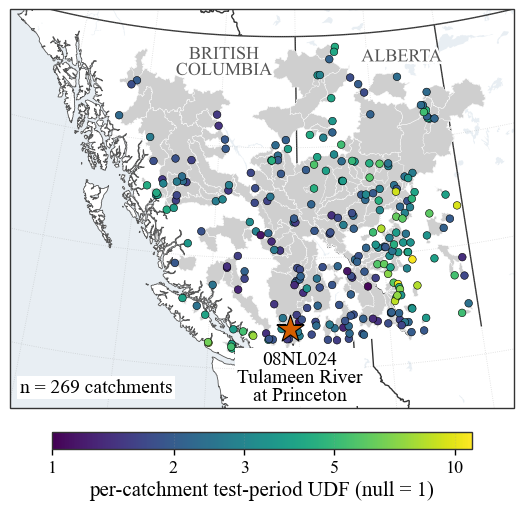

In [14]:
HM = 13.0
fig = plt.figure(figsize=(W, HM*CM))
ax = fig.add_axes([0.005, 0.215, 0.99, 0.78], projection=PROJ)
ax.set_extent([-135.0, -109.0, 45.9, 60.3], crs=ccrs.PlateCarree())
ax.add_feature(ne("physical", "ocean"), facecolor="#e8eef3", edgecolor="none", zorder=0)
ax.add_feature(ne("physical", "lakes"), facecolor="#e8eef3", edgecolor="none", zorder=1)
ax.add_feature(ne("physical", "coastline"), facecolor="none", edgecolor="#555555", lw=0.6, zorder=2)
ax.add_feature(ne("cultural", "admin_1_states_provinces_lines"), facecolor="none",
               edgecolor="#333333", lw=1.0, zorder=2)
ax.add_geometries(POLY.geometry, crs=PROJ, facecolor="#cfcfcf", edgecolor="white", lw=0.3, zorder=3)
gl = ax.gridlines(draw_labels=False, color="#999999", alpha=0.35, lw=0.6, ls=":",
                  xlocs=range(-135, -105, 5), ylocs=range(48, 62, 4))

# gauges coloured by per-catchment UDF on a log scale (null = 1)
pts = ST.loc[stations]
sc = ax.scatter(pts.longitude, pts.latitude, c=PB.loc[stations, "udf"], cmap="viridis",
                norm=LogNorm(1, 11), s=30, edgecolors="black", linewidths=0.4,
                transform=ccrs.PlateCarree(), zorder=5)
assert PB.udf.between(1, 11).all(), "a UDF falls outside the colour range"

# the hydrograph catchment
plon, plat = pts.loc[PICK, ["longitude", "latitude"]]
ax.scatter(plon, plat, marker="*", s=420, facecolor=CO, edgecolor="black", linewidths=0.8,
           transform=ccrs.PlateCarree(), zorder=7)
halo = [pe.withStroke(linewidth=3.5, foreground="white")]
# label south-east of the gauge, in Washington, where neither it nor its leader line
# touches another catchment (asserted below)
SHRINK_PT = 11                                                 # leader starts outside the star
_lab = NAMES[PICK].title().replace(" At ", "\nat ").replace(" Near ", "\nnear ")
_pc = ccrs.PlateCarree()._as_mpl_transform(ax)
lab = ax.annotate(f"{PICK}\n{_lab}", xy=(plon, plat), xycoords=_pc, xytext=(plon, plat), textcoords=_pc,
                  ha="center", va="top", fontsize=FS_ANN, linespacing=1.0, zorder=8,
                  bbox=dict(fc="white", ec="none", pad=1.5),
                  arrowprops=dict(arrowstyle="-", lw=1.0, color=CK, shrinkA=2, shrinkB=SHRINK_PT))

for txt, lon, lat in (("BRITISH\nCOLUMBIA", -125.0, 59.0), ("ALBERTA", -112.6, 59.0)):
    ax.text(lon, lat, txt, transform=ccrs.PlateCarree(), fontsize=FS_TICK, color="#555555",
            ha="center", va="center", linespacing=1.0, path_effects=halo, zorder=6)
ax.text(0.02, 0.03, f"n = {NBAS} catchments", transform=ax.transAxes, ha="left", va="bottom",
        fontsize=FS_ANN, bbox=dict(fc="white", ec="none", pad=2), zorder=9)

cax = fig.add_axes([0.20, 0.135, 0.60, 0.033])
cb = fig.colorbar(sc, cax=cax, orientation="horizontal")
cb.set_ticks([1, 2, 3, 5, 10]); cb.set_ticklabels(["1", "2", "3", "5", "10"]); cb.minorticks_off()
cb.ax.tick_params(labelsize=FS_TICK, width=1.0, length=4)
cb.set_label("per-catchment test-period UDF (null = 1)", fontsize=FS_LAB, labelpad=3)
# --- place the label: the closest candidate position (in the open area south of the
# gauge) where neither the label box nor its leader line touches any catchment except the
# pick and those containing its gauge (downstream catchments, which the star must overlap)
from shapely.geometry import Point, LineString, box
fig.canvas.draw(); _rend = fig.canvas.get_renderer()
_star = Point(*PROJ.transform_point(plon, plat, ccrs.PlateCarree()))
_own = sorted(set(POLY[POLY.contains(_star)].StationNum) | {PICK})
_others = POLY[~POLY.StationNum.isin(_own)].union_all()
_m_per_pt = np.diff(ax.get_xlim())[0] / (ax.get_window_extent().width*72/fig.dpi)
_hole = _star.buffer(SHRINK_PT*_m_per_pt)
_frame = box(*ax.get_xlim()[:1], ax.get_ylim()[0], ax.get_xlim()[1], ax.get_ylim()[1])

def _label_ok(lonlat):
    lab.xyann = lonlat
    lab.update_positions(_rend)                    # text box only: Annotation's own extent includes the leader
    bb = mpl.text.Text.get_window_extent(lab, _rend).transformed(ax.transData.inverted())
    tb = box(bb.x0, bb.y0, bb.x1, bb.y1)
    lead = LineString([_star, PROJ.transform_point(*lonlat, ccrs.PlateCarree())]).difference(_hole)
    return _frame.contains(tb) and not tb.intersects(_others) and not lead.intersects(_others)

_cands = sorted(((lo, la) for lo in np.arange(-130, -110, 0.25) for la in np.arange(46.5, 49.4, 0.1)),
                key=lambda c: Point(*PROJ.transform_point(*c, ccrs.PlateCarree())).distance(_star))
LABEL_AT = next(c for c in _cands if _label_ok(c))
assert _label_ok(LABEL_AT)
print(f"label at lon {LABEL_AT[0]:.2f}, lat {LABEL_AT[1]:.2f}: label box and leader line clear of every "
      f"catchment except {sorted(_own)}")
save(fig, "poster_map", HM); plt.show()

## §7 — Poster hydrograph

The chosen catchment over the six months Aug 2021 – Jan 2022 around its event. The band is $\hat\mu \pm 2$ corrected spread. The annotation gives that day's residual as a multiple of the corrected spread. On the main axes the band is a sliver next to the flood, which is honest, so the axis stays linear. An inset shows Sep–Oct at its own scale, where the band is visible and covers the observations.

inset: Sep-Oct band covers 98% of observed days
saved figures/poster/poster_hydrograph.{pdf,png}  17.75 x 8.00 cm  (2795 x 1259 px)


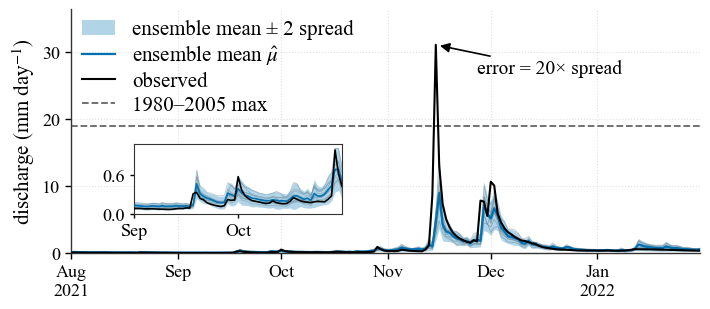

08NL024 Tulameen River At Princeton  event 2021-11-15: observed 31.08, mu-hat 4.61, corrected spread 1.339 mm/day; band upper edge 7.29; error/spread 19.77; 1.63x the 1980-2005 max (19.07 mm/day)


In [15]:
HH = 8.0
j = stations.index(PICK); e = EV.loc[PICK]
t_ev = e.event
win = (dates >= "2021-08-01") & (dates <= "2022-01-31")
assert t_ev in dates[win] and test[win].all(), "window must sit inside the test period"
d, yo, mh, sp, mem = dates[win], y[win, j], mu[win, j], spread[win, j], members[:, win, j]

fig, ax = plt.subplots(figsize=(W, HH*CM))
fig.subplots_adjust(left=0.085, right=0.985, bottom=0.20, top=0.975)
for k in range(M):                                                    # z-order 1: members
    ax.plot(d, mem[k], color="#9a9a9a", lw=0.6, alpha=0.6, zorder=1)
ax.fill_between(d, mh - 2*sp, mh + 2*sp, color=CP, alpha=0.3, lw=0, zorder=2,
                label="ensemble mean ± 2 spread")
ax.plot(d, mh, color=CP, lw=1.6, zorder=3, label=r"ensemble mean $\hat\mu$")
ax.plot(d, yo, color=CK, lw=1.5, zorder=4, label="observed")
ax.axhline(LEVELS.loc[PICK, "max"], color=CREF, ls="--", lw=1.3, zorder=2, label="1980–2005 max")

ANNOT = f"error = {e.err_over_spread:.0f}× spread"
ax.annotate(ANNOT, xy=(t_ev, e.obs),
            xytext=(t_ev + pd.Timedelta(days=12), e.obs*0.93), fontsize=FS_ANN, ha="left", va="top",
            arrowprops=dict(arrowstyle="-|>", lw=1.2, color=CK, shrinkB=3), zorder=6)
ax.set_xlim(d[0], d[-1]); ax.set_ylim(0, e.obs*1.17)
ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
# month ticks; the year is added under the first tick and under each January
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda x, pos: (lambda t: t.strftime("%b")
    + (t.strftime("\n%Y") if pos == 0 or t.month == 1 else ""))(mpl.dates.num2date(x))))
ax.set_ylabel(r"discharge (mm day$^{-1}$)")
ax.legend(loc="upper left", frameon=False, fontsize=FS_LEG, handlelength=1.6, labelspacing=0.2,
          borderaxespad=0.1)

# inset: Sep-Oct 2021 at its own scale, so the band can be seen where flows are ordinary
zi = (d >= "2021-09-01") & (d <= "2021-10-31")
axi = ax.inset_axes([0.10, 0.16, 0.33, 0.29])
for k in range(M): axi.plot(d[zi], mem[k, zi], color="#9a9a9a", lw=0.5, alpha=0.6, zorder=1)
axi.fill_between(d[zi], (mh - 2*sp)[zi], (mh + 2*sp)[zi], color=CP, alpha=0.3, lw=0, zorder=2)
axi.plot(d[zi], mh[zi], color=CP, lw=1.2, zorder=3); axi.plot(d[zi], yo[zi], color=CK, lw=1.2, zorder=4)
axi.set_xlim(d[zi][0], d[zi][-1]); axi.set_ylim(0, None)
axi.xaxis.set_major_locator(mpl.dates.MonthLocator()); axi.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b"))
axi.yaxis.set_major_locator(mpl.ticker.MaxNLocator(2)); axi.grid(False)
axi.tick_params(labelsize=FS_TICK, length=3); axi.set_facecolor("white")
for s in axi.spines.values(): s.set_visible(True); s.set_linewidth(0.8)
print(f"inset: Sep-Oct band covers {np.mean(np.abs(yo[zi]-mh[zi]) <= 2*sp[zi]):.0%} of observed days")
save(fig, "poster_hydrograph", HH); plt.show()

# outer edge of the band on the event day, for the report
print(f"{PICK} {NAMES[PICK].title()}  event {t_ev.date()}: observed {e.obs:.2f}, mu-hat {e.mu:.2f}, "
      f"corrected spread {e.spread:.3f} mm/day; band upper edge {e.mu + 2*e.spread:.2f}; "
      f"error/spread {e.err_over_spread:.2f}; {e.x_train_max:.2f}x the 1980-2005 max "
      f"({LEVELS.loc[PICK, 'max']:.2f} mm/day)")

## §8 — Report values

All values that go into the report below, printed from the arrays so that a rerun shows they still hold.

In [16]:
_r = EV.loc[PICK]
print(f"catchment      {PICK}  {NAMES[PICK].title()}")
print(f"area           {ST.loc[PICK, 'basin_area_km2']:.0f} km2;  glacier cover {ST.loc[PICK, 'glacier_pct']:.2f} %")
print(f"test NSE       {_r.nse:.3f}")
print(f"UDF            {_r.udf:.2f}   (all-catchment median {PB.udf.median():.2f})")
print(f"AUSE           {_r.ause:.3f}  (pooled all-test {AUSE_ALL:.3f})")
print(f"event          {_r.event.date()}: {_r.obs:.2f} mm/day observed vs mu-hat {_r.mu:.2f} +/- 2 x {_r.spread:.3f}")
print(f"exceedance     {_r.x_train_max:.2f}x the training max "
      f"{LEVELS.loc[PICK, 'max']:.2f} mm/day (p99 {LEVELS.loc[PICK, 'p99']:.2f})")
print(f"annotation     error/spread = {_r.err_over_spread:.2f} -> {ANNOT!r}")
print("counts         " + "; ".join(f"{k.strip()}: {v}" for k, v in COUNTS.items()))
print(f"map            UDF range {PB.udf.min():.2f}-{PB.udf.max():.2f}, all {int((PB.udf > 1).sum())}/{NBAS} > 1")

catchment      08NL024  Tulameen River At Princeton
area           1776 km2;  glacier cover 0.00 %
test NSE       0.830
UDF            1.81   (all-catchment median 2.33)
AUSE           0.128  (pooled all-test 0.071)
event          2021-11-15: 31.08 mm/day observed vs mu-hat 4.61 +/- 2 x 1.339
exceedance     1.63x the training max 19.07 mm/day (p99 7.25)
annotation     error/spread = 19.77 -> 'error = 20× spread'
counts         NSE >= 0.7: 150; test peak > 1980-2005 max: 103; of which in Nov 2021: 9; of which in the 14-17 Nov 2021 AR: 9
map            UDF range 1.03-10.78, all 269/269 > 1


## Report

**Chosen catchment: 08NL024, Tulameen River at Princeton, BC.** Area 1,776 km², no glacier cover. Test-period NSE 0.830. Per-catchment UDF 1.81, below the all-catchment median of 2.33. Per-catchment AUSE 0.128, against a pooled all-test value of 0.071.

**Selection (§6).**
- *Tier 1 (event):* the test-period peak exceeds the catchment's 1980–2005 maximum and falls in the 14–17 Nov 2021 atmospheric river. 9 catchments qualify.
- *Tier 2 (representative):* NSE ≥ 0.7, UDF ≤ median (2.33) and glacier < 5 %. 4 of the 9 pass: 08NL024, 08NL038, 08NL070 and 08MH016. Tulameen meets all three, so it looks fine on every aggregate diagnostic.
- *Tier 3 (tie-break):* exceedance ratio. Tulameen's 1.63× is the largest among the Tier-2 catchments. Four Tier-1 catchments have larger exceedances and Tier 2 excludes each one:
  - 08NL071 Tulameen below Vuich Creek, 2.79× (NSE 0.65, UDF 3.14)
  - 08LG048 Coldwater near Brookmere, 2.50× (NSE 0.71, but UDF 2.57 is above the median)
  - 08HA016 Bings Creek, 2.29× (NSE 0.48, UDF 5.36)
  - 08MH056 Slesse Creek, 1.97× (NSE 0.60, UDF 3.57)
- Error/spread was not a criterion. It is the result.

**Counts for the poster.**
- 150 of 269 catchments have test-period NSE ≥ 0.7.
- 103 of 269 had a test-period peak above their 1980–2005 maximum.
- 9 of those 103 peaked in November 2021, all of them during the 14–17 Nov atmospheric river.

**Event.** 15 November 2021. Observed 31.08 mm/day, which is 1.63× the 1980–2005 maximum of 19.07 mm/day; the 1980–2005 p99 is 7.25 mm/day. The ensemble mean was 4.61 mm/day with a corrected spread of 1.339 mm/day, so the band's upper edge was 7.29 mm/day.

**Annotation.** Residual / corrected spread = (31.08 − 4.61) / 1.339 = 19.77, printed as "error = 20× spread".

**Inset.** In Sep–Oct 2021, at its own scale, the ±2-spread band covers 98 % of observed days.

**Captions.**

- *Map:* "The 269 unregulated catchments in British Columbia and Alberta, each gauge coloured by its test-period under-dispersion factor (UDF; 1 = spread correctly sized). Every catchment is above 1 (range 1.03–10.8), and the star marks the hydrograph catchment."
- *Hydrograph:* "Tulameen River at Princeton (08NL024) during the November 2021 atmospheric-river flood. The observed peak was 1.6× the largest flow in the 1980–2005 training record and fell 20 ensemble spreads above the ensemble mean, far outside the ±2-spread band."
- *Fig. 1:* "Ensemble spread understates error in every flow decile. Conditioned on the model's own prediction, the shortfall grows from 2.1× to 4.3× (log–log slope 1.30), so no constant rescaling can fix it."
- *Fig. 2:* "The spread ranks errors well (AUSE 0.071) but sizes them badly. Across catchments, ranking quality and sizing are negatively correlated (ρ = −0.23), and even the best-ranking catchments under-disperse by a median 3.4×."
